# Ujian Tengah Semester Graf Sains Data
---

### Identitas Mahasiswa & Parameter Pengerjaan:
- **Nama Mahasiswa :** Ivanagita Mayang Palupi
- **NIM            :** 23031554009
- **Kelas          :** 2023 D
- **Periode Waktu P1 (Training):** 08 – 21 Juli 2015 (2 minggu / 14 hari)
- **Periode Waktu P2 (Testing) :** 22 – 28 Juli 2015 (1 minggu / 7 hari)
- **Environment    :** Local Python (Windows Environment tanpa venv)
- **Database Server:** Neo4j Community / Enterprise v2026.09 (`bolt://localhost:7687` / `http://localhost:7474`)
- **Driver Resmi   :** `neo4j` Python Driver (v6.4)

---

## 1. Tugas Pendahuluan

### 1.1 Persiapan dan Perkenalan Lingkungan
Pada pengerjaan UTS ini, seluruh proses analisis dan eksekusi dijalankan langsung menggunakan **Environment Lokal (Python 3.11)** di sistem operasi Windows tanpa perlu mengaktifkan venv terpisah, karena seluruh dependensi yang disyaratkan dalam `requirements.txt` telah terinstal dan terverifikasi secara penuh pada Python lokal.

In [3]:
# 1.1 Verifikasi Environment & Import Library Utama
import os
import sys
import time
import random
import datetime
import argparse
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import networkx as nx
from tqdm.auto import tqdm
from scipy.sparse import csr_matrix
from sklearn.preprocessing import normalize

# Import resmi Neo4j Driver (sesuai Halaman 2 modul soal)
from neo4j import GraphDatabase, RoutingControl

print(" Environment dan Library berhasil diverifikasi:")
print(f"  - Python Executable : {sys.executable}")
print(f"  - Python Version    : {sys.version.split()[0]}")
print(f"  - pandas: {pd.__version__} | numpy: {np.__version__} | networkx: {nx.__version__}")


 Environment dan Library berhasil diverifikasi:
  - Python Executable : C:\Users\IVANAGITA\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe
  - Python Version    : 3.11.9
  - pandas: 2.3.3 | numpy: 1.26.4 | networkx: 3.6.1


### 1.2 Mempelajari Penggunaan Driver Neo4J

In [9]:
# ─── Kode Tutorial ───
from neo4j import GraphDatabase, RoutingControl

# String koneksi ke database Neo4j
URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "neo4j") 

# Fungsi membuat simpul Person beserta relasi pertemanan KNOWS
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j",
    )

# Fungsi mencetak dan membaca relasi pertemanan
def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(f"  - {record['friend.name']}")

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print("Daftar teman Arthur (hasil print_friends):")
    print_friends(driver, "Arthur")

    

Daftar teman Arthur (hasil print_friends):
  - Guinevere
  - Lancelot
  - Merlin


### Pertanyaan Pendahuluan (Checkpoint) — Jawaban Lengkap

1. **Apa nama database yang digunakan pada tutorial ini?**  
   Database yang digunakan secara default adalah **`neo4j`** dan didalamnya terdapat database sistem bawaan bernama **`system`** yang bertugas mengelola autentikasi pengguna, hak akses (roles), serta konfigurasi multitenant instance Neo4j.


2. **Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses database lain dalam 1 instance!** 
 
   | Cara | Contoh |
   |---|---|
   | Melihat daftar database | `SHOW DATABASES` / `SHOW DATABASE neo4j` |
   | Berpindah database di Neo4j Browser / cypher-shell | `:use system` atau `:use namadb` |
   | Klausa `USE` di dalam query Cypher | `USE namadb MATCH (n) RETURN count(n)` |
   | Membuat / menghapus database (Enterprise) | `CREATE DATABASE namadb`, `DROP DATABASE namadb` |
   | Menyalakan / mematikan database (Enterprise) | `START DATABASE namadb`, `STOP DATABASE namadb` |
   | Dari Python driver | `driver.session(database="namadb")` (4.x) atau `execute_query(..., database_="namadb")` (5.x) |


3. **Apa jenis graf pertemanan yang telah dibuat di sini?**  
   - **Berarah (directed)**: relasi `(a)-[:KNOWS]->(friend)` punya arah dari Arthur ke temannya; Guinevere/Lancelot/Merlin tidak punya relasi balik ke Arthur.
   - **Tidak berbobot (unweighted)**: relasi `KNOWS` tidak memiliki properti bobot.
   - **Homogen**: hanya ada satu jenis node (`Person`) dan satu jenis relasi (`KNOWS`).
   - **Berbentuk bintang (star graph / tree)**: Arthur sebagai pusat (out-degree 3), tiga node lain sebagai daun (in-degree 1), tanpa siklus.
---
### CYPHER Total Reset

In [10]:
# CYPHER Total Reset 
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.execute_query("MATCH (n) DETACH DELETE n;", database_="neo4j")
print("Database Neo4j berhasil di-reset bersih dengan CYPHER Total Reset (MATCH (n) DETACH DELETE n).")


Database Neo4j berhasil di-reset bersih dengan CYPHER Total Reset (MATCH (n) DETACH DELETE n).


### 1.3 Melakukan Proses Impor Data dari RetailRocket ke Database Neo4J
- Sumber dataset: RetailRocket E-Commerce Dataset (Roman Zykov).
- Rincian fitur dataset `events.csv`:
  1. `timestamp`: Waktu interaksi dalam format Unix epoch milliseconds.
  2. `visitorid`: ID unik pengunjung (pengguna).
  3. `event`: Jenis interaksi (`view`, `addtocart`, `transaction`).
  4. `itemid`: ID unik produk / barang.
  5. `transactionid`: ID transaksi (hanya terisi saat event berjenis `transaction`).

In [11]:
# Fungsi Argument Parser (Pembuatan session Neo4J) 
def parse_arguments():
    parser = argparse.ArgumentParser(
        description="Impor dataset RetailRocket (events.csv) ke database Neo4J."
    )
    parser.add_argument(
        "-u", "--user", default="neo4j", help="Username Neo4j (default: neo4j)"
    )
    parser.add_argument(
        "-p",
        "--password",
        default="neo4j",
        help="Password Neo4J (default: neo4j)"
    )
    parser.add_argument(
        "-b",
        "--bolt",
        default="neo4j://localhost:7687",
        help="Neo4J URI / Bolt"
    )
    parser.add_argument(
        "-s", 
        "--source", 
        default="archive", 
        help="Direktori sumber data (default: archive)"
    )
    
    args, _ = parser.parse_known_args()
    return args

args = parse_arguments()
csv_file_path = os.path.join(args.source, "events.csv")

# Pemeriksaan keberadaan berkas events.csv
if not os.path.exists(csv_file_path):
    print(f"Error: File '{csv_file_path}' tidak ditemukan!")
    sys.exit(1)
else:
    print(f"File '{csv_file_path}' ditemukan ({os.path.getsize(csv_file_path)/(1024*1024):.1f} MB)")

# Pembuatan koneksi driver 
try:
    driver = GraphDatabase.driver(
        args.bolt, auth=(args.user, args.password)
    )
    driver.verify_connectivity()
    print("Berhasil terhubung ke database Neo4j!")
except Exception as e:
    print(f"Gagal terhubung ke database: {e}")
    sys.exit(1)


File 'archive\events.csv' ditemukan (89.9 MB)
Berhasil terhubung ke database Neo4j!


---
## 2. Soal UTS

---
### 2.1 Wrangling dan EDA (Maks. Skor: 45)

#### Soal 1 : Menentukan 2 Periode Waktu
- **P1 (Training Fold):** 08 – 21 Juli 2015 (14 hari / 2 minggu)
- **P2 (Testing Fold):** 22 – 28 Juli 2015 (7 hari / 1 minggu)

In [12]:
# Fungsi konversi string tanggal UTC ke Unix epoch ms
def to_ms(dt_str):
    return int(datetime.datetime.strptime(dt_str, '%Y-%m-%d %H:%M:%S').replace(
        tzinfo=datetime.timezone.utc).timestamp() * 1000)

P1_START = to_ms('2015-07-08 00:00:00')
P1_END   = to_ms('2015-07-21 23:59:59')
P2_START = to_ms('2015-07-22 00:00:00')
P2_END   = to_ms('2015-07-28 23:59:59')

print("=== BATAS TIMESTAMP PENGERJAAN UTS ===")
print(f"P1 (Training): {P1_START} s.d. {P1_END} (08-21 Juli 2015)")
print(f"P2 (Testing) : {P2_START} s.d. {P2_END} (22-28 Juli 2015)")

=== BATAS TIMESTAMP PENGERJAAN UTS ===
P1 (Training): 1436313600000 s.d. 1437523199000 (08-21 Juli 2015)
P2 (Testing) : 1437523200000 s.d. 1438127999000 (22-28 Juli 2015)


---
#### Soal 2 : Menerapkan Filter P1 & P2, Lalu Simpan Dalam File .csv

In [14]:
# Terapkan filter P1 & P2 pada data events.csv
events_df = pd.read_csv(csv_file_path)
events_p1 = events_df[(events_df['timestamp'] >= P1_START) & (events_df['timestamp'] <= P1_END)].copy()
events_p2 = events_df[(events_df['timestamp'] >= P2_START) & (events_df['timestamp'] <= P2_END)].copy()

print(f"\nHasil Filter events.csv:")
print(f"  - Events P1 (Training): {len(events_p1):,} baris")
print(f"  - Events P2 (Testing) : {len(events_p2):,} baris")

# Filter item properties (part 1 & part 2 snapshot mingguan)
print("\nMemfilter item_properties_part1.csv dan part2.csv ...")
p1_chunks, p2_chunks = [], []
for fname in ['item_properties_part1.csv', 'item_properties_part2.csv']:
    fpath = os.path.join(args.source, fname)
    for ch in pd.read_csv(fpath, chunksize=1_000_000):
        m1 = (ch['timestamp'] >= P1_START) & (ch['timestamp'] <= P1_END)
        m2 = (ch['timestamp'] >= P2_START) & (ch['timestamp'] <= P2_END)
        if m1.any(): p1_chunks.append(ch[m1])
        if m2.any(): p2_chunks.append(ch[m2])

item_props_p1 = pd.concat(p1_chunks, ignore_index=True)
item_props_p2 = pd.concat(p2_chunks, ignore_index=True)

# Simpan ke dalam berkas CSV sesuai soal No. 2
events_p1.to_csv('events_p1_training.csv', index=False)
events_p2.to_csv('events_p2_testing.csv', index=False)
item_props_p1.to_csv('item_properties_p1.csv', index=False)
item_props_p2.to_csv('item_properties_p2.csv', index=False)

print("\Berkas .csv berhasil disimpan:")
for f in ['events_p1_training.csv', 'events_p2_testing.csv', 'item_properties_p1.csv', 'item_properties_p2.csv']:
    print(f"  - {f:<26} ({os.path.getsize(f)/(1024*1024):.2f} MB)")



Hasil Filter events.csv:
  - Events P1 (Training): 316,292 baris
  - Events P2 (Testing) : 177,033 baris

Memfilter item_properties_part1.csv dan part2.csv ...
\Berkas .csv berhasil disimpan:
  - events_p1_training.csv     (10.62 MB)
  - events_p2_testing.csv      (5.94 MB)
  - item_properties_p1.csv     (53.02 MB)
  - item_properties_p2.csv     (24.87 MB)


---
#### Soal 3 — Impor Subgraf ke Neo4j & Query Komposisi Subgraf

- Fungsi `create_constraints(session)` membuat indeks unik.
- Fungsi `import_batch(tx, batch)` mengimpor data interaksi ke Neo4j menggunakan CYPHER.

In [15]:
# Fungsi membuat constraints unik 
def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

# Fungsi import batch 
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})
    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
    UNION ALL
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
    UNION ALL
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

# Filter pengunjung yang terhubung P1 & P2 untuk subgraf interaksi
v1_set = set(events_p1['visitorid'].unique())
v2_set = set(events_p2['visitorid'].unique())
common_visitors = v1_set.intersection(v2_set)

sub_events = events_p1[events_p1['visitorid'].isin(common_visitors)].copy()
sub_events['transactionid'] = sub_events['transactionid'].fillna('').astype(str)
records = sub_events.to_dict(orient="records")

batch_size = 2000
total_chunks = (len(records) // batch_size) + 1

print(f"Memulai proses impor data subgraf ke Neo4j ({len(records):,} baris interaksi)...")
t0 = time.time()
with driver.session() as session:
    create_constraints(session)
    for i in tqdm(range(0, len(records), batch_size), total=total_chunks, desc="Mengimpor Batch Data"):
        batch = records[i:i + batch_size]
        session.execute_write(import_batch, batch)

print(f"Proses impor subgraf berhasil dalam {time.time() - t0:.2f} detik.")


Memulai proses impor data subgraf ke Neo4j (31,726 baris interaksi)...


Mengimpor Batch Data: 100%|██████████| 16/16 [00:10<00:00,  1.49it/s]

Proses impor subgraf berhasil dalam 13.13 detik.


In [16]:
# Query Komposisi Subgraph Menggunakan Python API
with driver.session() as session:
    # 1. Hitung simpul per jenis label
    res_nodes = session.run("""
    MATCH (n) 
    RETURN labels(n)[0] AS tipe_simpul, count(n) AS jumlah 
    ORDER BY jumlah DESC
    """)
    nodes_data = [(r['tipe_simpul'], r['jumlah']) for r in res_nodes]
    
    # 2. Hitung relasi per jenis relasi
    res_rels = session.run("""
    MATCH ()-[r]->() 
    RETURN type(r) AS jenis_relasi, count(r) AS jumlah 
    ORDER BY jumlah DESC
    """)
    rels_data = [(r['jenis_relasi'], r['jumlah']) for r in res_rels]

print("=" * 55)
print("KOMPOSISI SUBGRAF DI DATABASE NEO4J")
print("=" * 55)
print("[SIMPUL / NODES]")
total_n = 0
for tipe, cnt in nodes_data:
    print(f"  - Label {tipe:<12} : {cnt:>8,} simpul")
    total_n += cnt
print(f"  * Total Simpul       : {total_n:>8,} simpul\n")

print("[RELASI / EDGES]")
total_e = 0
for jenis, cnt in rels_data:
    print(f"  - Tipe {jenis:<13} : {cnt:>8,} relasi")
    total_e += cnt
print(f"  * Total Relasi       : {total_e:>8,} relasi")
print("=" * 55)


KOMPOSISI SUBGRAF DI DATABASE NEO4J
[SIMPUL / NODES]
  - Label Item         :   14,062 simpul
  - Label Visitor      :    5,116 simpul
  * Total Simpul       :   19,178 simpul

[RELASI / EDGES]
  - Tipe VIEWED        :   29,514 relasi
  - Tipe ADDED_TO_CART :    1,538 relasi
  - Tipe BOUGHT        :      674 relasi
  * Total Relasi       :   31,726 relasi


#### **Uraian Penjelasan Kueri CYPHER yang Digunakan:**
1. **Kueri Komposisi Simpul:**
   ```cypher
   MATCH (n) 
   RETURN labels(n)[0] AS tipe_simpul, count(n) AS jumlah 
   ORDER BY jumlah DESC
   ```
   * `MATCH (n)`: Menelusuri seluruh simpul pada database aktif.
   * `labels(n)[0]`: Mengambil nama label simpul utama (`Item` atau `Visitor`).
   * `count(n)`: Menghitung frekuensi kemunculan simpul untuk setiap label.
   * `ORDER BY jumlah DESC`: Mengurutkan label simpul berdasarkan jumlah terbanyak.

2. **Kueri Komposisi Relasi:**
   ```cypher
   MATCH ()-[r]->() 
   RETURN type(r) AS jenis_relasi, count(r) AS jumlah 
   ORDER BY jumlah DESC
   ```
   * `MATCH ()-[r]->()`: Menelusuri semua relasi berarah antar simpul mana pun.
   * `type(r)`: Mengidentifikasi tipe relasi (`VIEWED`, `ADDED_TO_CART`, `BOUGHT`).
   * `count(r)`: Menghitung total banyaknya relasi yang terbentuk per tipe.

#### Soal 4 — Vector Space Modelling (VSM) terhadap Simpul User (Visitor)
- Pembobotan interaksi e-commerce:
  $$\text{view} = 1, \quad \text{addtocart} = 2, \quad \text{transaction} = 3$$
- Matriks User–Item $A$ dibentuk dengan dimensi $N_{\text{user}} \times N_{\text{item}}$.
- Normalisasi baris L2 ($A_{\text{norm}}$) untuk menghitung proyeksi unipartite User–User:
  $$U = A_{\text{norm}} \cdot A_{\text{norm}}^T$$
  di mana $U_{ij}$ menyatakan nilai Cosine Similarity antara profil pengunjung $i$ dan $j$.

In [17]:
# Membuat Matriks Interaksi User-Item
EVENT_WEIGHT = {'view': 1, 'addtocart': 2, 'transaction': 3}
sub_events_w = sub_events.copy()
sub_events_w['weight'] = sub_events_w['event'].map(EVENT_WEIGHT)

ui_agg = sub_events_w.groupby(['visitorid', 'itemid'])['weight'].sum().reset_index()

visitors_list = sorted(ui_agg['visitorid'].unique())
items_list    = sorted(ui_agg['itemid'].unique())
visitor_idx   = {v: i for i, v in enumerate(visitors_list)}
item_idx      = {it: i for i, it in enumerate(items_list)}

rows_u = ui_agg['visitorid'].map(visitor_idx).values
cols_i = ui_agg['itemid'].map(item_idx).values
vals_w = ui_agg['weight'].values

USER_ITEM_SPARSE = csr_matrix((vals_w, (rows_u, cols_i)), shape=(len(visitors_list), len(items_list)))

# Normalisasi L2 per baris User
A_u_norm = normalize(USER_ITEM_SPARSE, norm='l2', axis=1)

# Proyeksi User-User
UU_sparse = A_u_norm @ A_u_norm.T
UU_sparse.setdiag(0)
UU_sparse.eliminate_zeros()

n_users = len(visitors_list)
print("KARAKTERISTIK VSM SIMPUL USER")
print(f"Dimensi Matriks User-Item : {USER_ITEM_SPARSE.shape[0]:,} User x {USER_ITEM_SPARSE.shape[1]:,} Item")
print(f"Sparsity Matriks User-Item: {1.0 - (USER_ITEM_SPARSE.nnz / (n_users * len(items_list))):.4%}")
print(f"Non-Zero Entries          : {USER_ITEM_SPARSE.nnz:,}")
print(f"Dimensi Proyeksi User-User: {UU_sparse.shape}")
print(f"Pasangan User Similar (>0): {UU_sparse.nnz:,} pasangan")
print(f"Nilai Cosine Maksimum     : {UU_sparse.data.max():.4f}")
print(f"Rata-rata Nilai Cosine    : {UU_sparse.data.mean():.4f}")


KARAKTERISTIK VSM SIMPUL USER
Dimensi Matriks User-Item : 5,116 User x 14,062 Item
Sparsity Matriks User-Item: 99.9726%
Non-Zero Entries          : 19,679
Dimensi Proyeksi User-User: (5116, 5116)
Pasangan User Similar (>0): 16,824 pasangan
Nilai Cosine Maksimum     : 1.0000
Rata-rata Nilai Cosine    : 0.1847


Subgraf Proyeksi User (Top 100 User Paling Aktif):
  Simpul (Nodes) : 100
  Tepi (Edges)   : 119


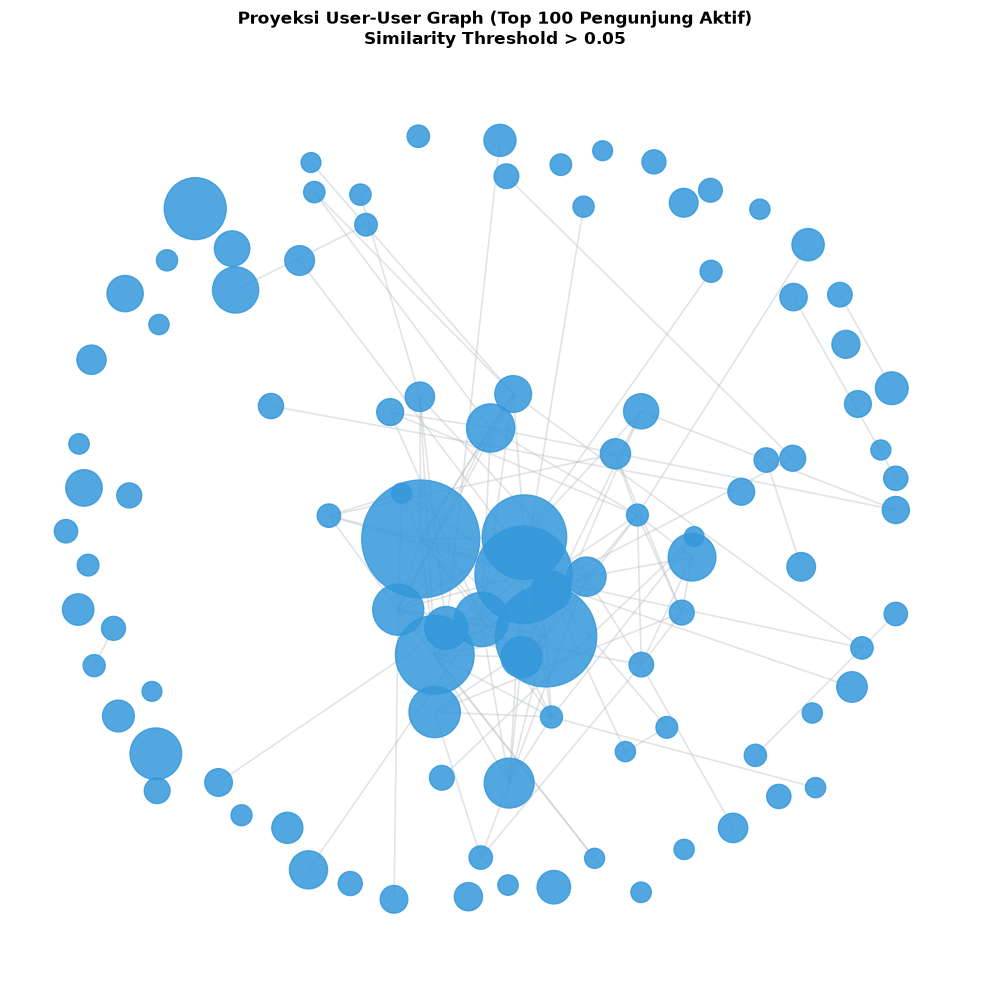

In [27]:
# Visualisasi NetworkX Proyeksi User-User (Top 100 User Teraktif)
top_k_users = 100
user_activity = np.array(USER_ITEM_SPARSE.sum(axis=1)).flatten()
top_u_idx = np.argsort(user_activity)[::-1][:top_k_users]

G_user = nx.Graph()
for idx in top_u_idx:
    G_user.add_node(visitors_list[idx], weight=user_activity[idx])

SIM_THRESHOLD_U = 0.05
UU_sub = (A_u_norm[top_u_idx] @ A_u_norm[top_u_idx].T).toarray()
np.fill_diagonal(UU_sub, 0)

for i in range(top_k_users):
    for j in range(i + 1, top_k_users):
        sim = UU_sub[i, j]
        if sim > SIM_THRESHOLD_U:
            G_user.add_edge(visitors_list[top_u_idx[i]], visitors_list[top_u_idx[j]], weight=sim)

print(f"Subgraf Proyeksi User (Top {top_k_users} User Paling Aktif):")
print(f"  Simpul (Nodes) : {G_user.number_of_nodes()}")
print(f"  Tepi (Edges)   : {G_user.number_of_edges()}")

plt.figure(figsize=(10, 10))
pos_u = nx.spring_layout(G_user, seed=42, k=0.35)
node_sizes_u = [G_user.nodes[n]['weight'] * 4 + 40 for n in G_user.nodes()]

nx.draw_networkx_nodes(G_user, pos_u, node_size=node_sizes_u, node_color='#3498db', alpha=0.85)
nx.draw_networkx_edges(G_user, pos_u, edge_color='#bdc3c7', alpha=0.45, width=1.2)
plt.title(f'Proyeksi User-User Graph (Top {top_k_users} Pengunjung Aktif)\nSimilarity Threshold > {SIM_THRESHOLD_U}',
          fontsize=12, fontweight='bold', pad=12)
plt.axis('off')
plt.tight_layout()
plt.savefig('user_projection_graph.png', dpi=150, bbox_inches='tight')
plt.show()


---
#### Soal 5 — Vector Space Modelling (VSM) terhadap Simpul Item
- Normalisasi kolom L2 ($A_{	{norm\_item}}$) digunakan untuk menghitung proyeksi unipartite Item–Item:
  $$I = A_{	{norm\_item}}^T \cdot A_{	{norm\_item}}$$
  di mana $I_{kl}$ menyatakan nilai Cosine Similarity antara produk $k$ dan $l$ berdasarkan kemiripan audiens pengunjungnya.

In [23]:
# Normalisasi L2 per kolom Item
A_i_norm = normalize(USER_ITEM_SPARSE, norm='l2', axis=0)

# Proyeksi Item-Item
II_sparse = A_i_norm.T @ A_i_norm
II_sparse.setdiag(0)
II_sparse.eliminate_zeros()

n_items = len(items_list)
print("KARAKTERISTIK VSM SIMPUL ITEM")
print(f"Dimensi Proyeksi Item-Item: {II_sparse.shape[0]:,} Item x {II_sparse.shape[1]:,} Item")
print(f"Pasangan Item Similar (>0): {II_sparse.nnz:,} pasangan")
print(f"Kepadatan Relasi (Density): {II_sparse.nnz / (n_items * n_items):.4%}")
print(f"Nilai Cosine Maksimum     : {II_sparse.data.max():.4f}")
print(f"Rata-rata Nilai Cosine    : {II_sparse.data.mean():.4f}")


KARAKTERISTIK VSM SIMPUL ITEM
Dimensi Proyeksi Item-Item: 14,062 Item x 14,062 Item
Pasangan Item Similar (>0): 2,521,602 pasangan
Kepadatan Relasi (Density): 1.2752%
Nilai Cosine Maksimum     : 1.0000
Rata-rata Nilai Cosine    : 0.5840


Subgraf Proyeksi Item (Top 100 Produk Terpopuler):
  Simpul (Nodes) : 100
  Tepi (Edges)   : 622


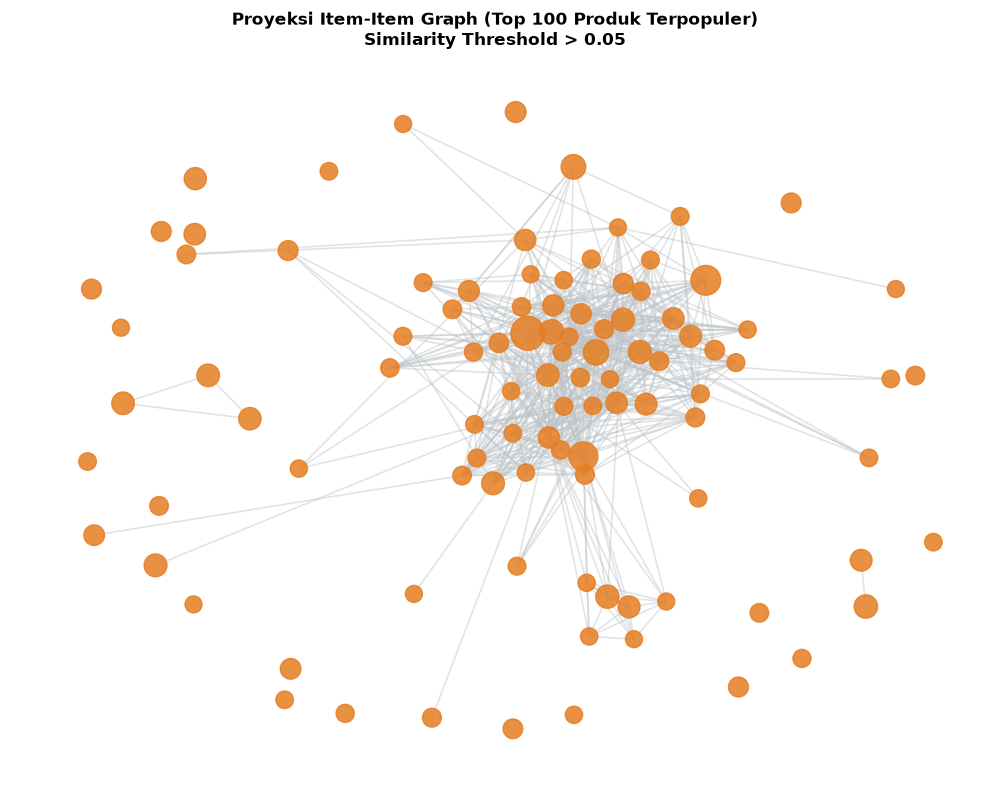

In [26]:
# Visualisasi NetworkX Proyeksi Item-Item (Top 100 Produk Terpopuler)
top_k_items = 100
item_popularity = np.array(USER_ITEM_SPARSE.sum(axis=0)).flatten()
top_i_idx = np.argsort(item_popularity)[::-1][:top_k_items]

G_item = nx.Graph()
for idx in top_i_idx:
    G_item.add_node(items_list[idx], weight=item_popularity[idx])

SIM_THRESHOLD_I = 0.05
II_sub = (A_i_norm[:, top_i_idx].T @ A_i_norm[:, top_i_idx]).toarray()
np.fill_diagonal(II_sub, 0)

for i in range(top_k_items):
    for j in range(i + 1, top_k_items):
        sim = II_sub[i, j]
        if sim > SIM_THRESHOLD_I:
            G_item.add_edge(items_list[top_i_idx[i]], items_list[top_i_idx[j]], weight=sim)

print(f"Subgraf Proyeksi Item (Top {top_k_items} Produk Terpopuler):")
print(f"  Simpul (Nodes) : {G_item.number_of_nodes()}")
print(f"  Tepi (Edges)   : {G_item.number_of_edges()}")

plt.figure(figsize=(10, 8))
pos_i = nx.spring_layout(G_item, seed=42, k=0.35)
node_sizes_i = [G_item.nodes[n]['weight'] * 5 + 40 for n in G_item.nodes()]

nx.draw_networkx_nodes(G_item, pos_i, node_size=node_sizes_i, node_color='#e67e22', alpha=0.85)
nx.draw_networkx_edges(G_item, pos_i, edge_color='#bdc3c7', alpha=0.45, width=1.2)
plt.title(f'Proyeksi Item-Item Graph (Top {top_k_items} Produk Terpopuler)\nSimilarity Threshold > {SIM_THRESHOLD_I}',
          fontsize=12, fontweight='bold', pad=12)
plt.axis('off')
plt.tight_layout()
plt.savefig('item_projection_graph.png', dpi=150, bbox_inches='tight')
plt.show()


---
#### Soal 6 — Uraian Komparasi: Proyeksi Mana yang Lebih Baik (Efektif/Efisien)?

In [32]:
komparasi_df = pd.DataFrame({
    'Parameter Metrik': [
        'Dimensi Ruang Vektor',
        'Total Simpul Terproyeksi',
        'Total Pasangan Similaritas Non-Zero',
        'Kepadatan Relasi (Density %)',
        'Rata-rata Cosine Similarity (>0)',
        'Nilai Cosine Maksimum',
        'Stabilitas Karakteristik E-Commerce'
    ],
    'Proyeksi User-User': [
        f"{UU_sparse.shape[0]:,} x {UU_sparse.shape[1]:,}",
        f"{n_users:,} Pengunjung",
        f"{UU_sparse.nnz:,}",
        f"{UU_sparse.nnz / (n_users*n_users):.4%}",
        f"{UU_sparse.data.mean():.4f}",
        f"{UU_sparse.data.max():.4f}",
        "Rendah (User sering churn / cold start)"
    ],
    'Proyeksi Item-Item': [
        f"{II_sparse.shape[0]:,} x {II_sparse.shape[1]:,}",
        f"{n_items:,} Item Produk",
        f"{II_sparse.nnz:,}",
        f"{II_sparse.nnz / (n_items*n_items):.4%}",
        f"{II_sparse.data.mean():.4f}",
        f"{II_sparse.data.max():.4f}",
        "Tinggi (Katalog produk relatif stabil)"
    ]
})

komparasi_df


,Parameter Metrik,Proyeksi User-User,Proyeksi Item-Item
0,Dimensi Ruang Vektor,"5,116 x 5,116","14,062 x 14,062"
1,Total Simpul Terproyeksi,"5,116 Pengunjung","14,062 Item Produk"
2,Total Pasangan Similaritas Non-Zero,"16,824","2,521,602"
3,Kepadatan Relasi (Density %),0.0643%,1.2752%
4,Rata-rata Cosine Similarity (>0),0.1847,0.5840
5,Nilai Cosine Maksimum,1.0000,1.0000
6,Stabilitas Karakteristik E-Commerce,Rendah (User sering churn / cold start),Tinggi (Katalog produk relatif stabil)


**Efektivitas Informasi & Kepadatan Sinyal (Informative & Dense Signal):**
 - **Kepadatan Relasi (Density):** Proyeksi Item-Item memiliki tingkat kerapatan relasi yang jauh lebih kaya dibandingkan Proyeksi User-User, yakni sebesar .2752% (2.521.602 pasangan non-zero), dibanding dengan 0.0643% (hanya 16.824 pasangan).
 - **Kekuatan Kemiripan (Cosine Similarity):** Rata-rata cosine similarity pada Item-Item lebih tinggi, yakni mencapai 0.5840, dibanding dengan User-User yang hanya **0.1847**. Nilai yang lebih tinggi ini menunjukkan bahwa pola interaksi pengguna terhadap item membentuk korelasi co-interaction yang kuat dan tajam antar-produk.



**Efisiensi & Stabilitas Komputasi (Computational Efficiency & Stability):**
 - **Stabilitas Katalog Produk:** Katalog produk e-commerce cenderung jauh lebih jarang berubah (relatif konstan). Oleh karena itu, matriks kemiripan Item-Item dapat dihitung secara offline / pre-computed dan disimpan (cached) tanpa perlu sering dihitung ulang.
 - **Dinamika Pengguna (Cold Start & Churn):** Profil pengguna berubah sangat cepat, memiliki sifat churn tinggi, dan pengunjung baru (cold start) terus bermunculan. Jika menggunakan User-User, sistem harus terus-menerus menghitung ulang matriks proyeksi setiap kali ada aktivitas user baru, yang sangat tidak efisien secara komputasi.

**Kesimpulan:** 
  Sesuai dengan prinsip Item-Based Collaborative Filtering (Sarwar et al., 2001), Proyeksi Item-Item dipilih sebagai pendekatan terbaik karena terbukti memberikan sinyal rekomendasi yang jauh lebih kaya (richer pattern) sekaligus efisien dalam pemrosesan sistem e-commerce berskala besar.

---
#### Soal 7 — Perhitungan Similarity pada Graf Terproyeksi & Simpan ke Neo4j
- **Item Acuan:** Dipilih item terpopuler pada periode P1.
- Menghitung Cosine Similarity antara item acuan terhadap seluruh item dalam graf.
- Relasi baru `[:SIMILAR_TO]` disimpan ke dalam Neo4j dengan properti `cosine`.

In [34]:
# 7a. Pilih Item Acuan & Hitung Top 5 Records Similarity Tertinggi
item_counts = sub_events['itemid'].value_counts()
ANCHOR_ITEM_ID = int(item_counts.index[0])

anchor_c_idx = item_idx[ANCHOR_ITEM_ID]
anchor_vec = A_i_norm[:, anchor_c_idx]

sim_scores = (A_i_norm.T @ anchor_vec).toarray().flatten()
sim_scores[anchor_c_idx] = 0

top5_indices = np.argsort(sim_scores)[::-1][:5]
top5_similar_items = [
    (int(items_list[idx]), float(sim_scores[idx])) 
    for idx in top5_indices
]

print(f"Item Acuan Terpilih : itemId = {ANCHOR_ITEM_ID} ({item_counts.iloc[0]} interaksi)\n")
print(f"Top 5 Records Similarity Tertinggi untuk Item Acuan ({ANCHOR_ITEM_ID}):")
print(f"{'Rank':<6} {'Anchor Item':<14} {'Target Item':<14} {'Cosine Similarity':<18}")
print("-" * 55)
for r, (tgt, sc) in enumerate(top5_similar_items, 1):
    print(f"{r:<6} {ANCHOR_ITEM_ID:<14} {tgt:<14} {sc:<18.6f}")


Item Acuan Terpilih : itemId = 445351 (84 interaksi)

Top 5 Records Similarity Tertinggi untuk Item Acuan (445351):
Rank   Anchor Item    Target Item    Cosine Similarity 
-------------------------------------------------------
1      445351         213834         0.795874          
2      445351         174189         0.741941          
3      445351         130371         0.702648          
4      445351         25762          0.692935          
5      445351         146613         0.676475          


In [35]:
# 7b. Tuliskan Kembali Nilai Similarity ke Graf Neo4j
cypher_write_sim = """
UNWIND $records AS row
MATCH (a:Item {itemId: row.itemId1})
MATCH (b:Item {itemId: row.itemId2})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.cosine = row.cosine
"""

sim_payload = [
    {'itemId1': int(ANCHOR_ITEM_ID), 'itemId2': int(tgt), 'cosine': float(score)}
    for tgt, score in top5_similar_items
]

with driver.session() as session:
    session.run(cypher_write_sim, records=sim_payload)

print(f"Berhasil menuliskan {len(sim_payload)} relasi [:SIMILAR_TO] ke database Neo4j.\n")

# Kueri CYPHER SQL untuk membuktikan nilai similarity tersimpan
cypher_read_sim = f"""
MATCH (anchor:Item {{itemId: {ANCHOR_ITEM_ID}}})-[s:SIMILAR_TO]->(target:Item)
RETURN anchor.itemId AS anchorItem,
       target.itemId AS similarItem,
       s.cosine      AS cosineSimilarity
ORDER BY s.cosine DESC
LIMIT 5
"""

print("Kueri CYPHER SQL Pembuktian:")
print(cypher_read_sim.strip())

with driver.session() as session:
    result_neo = session.run(cypher_read_sim)
    neo_rows = [(r['anchorItem'], r['similarItem'], r['cosineSimilarity']) for r in result_neo]

print("\nHasil Query CYPHER dari Database Neo4j:")
print(f"{'Rank':<6} {'Anchor Item':<14} {'Similar Item':<14} {'Cosine Similarity':<18}")
print("-" * 55)
for r, (anc, sim_itm, cs) in enumerate(neo_rows, 1):
    print(f"{r:<6} {anc:<14} {sim_itm:<14} {cs:<18.6f}")


Berhasil menuliskan 5 relasi [:SIMILAR_TO] ke database Neo4j.

Kueri CYPHER SQL Pembuktian:
MATCH (anchor:Item {itemId: 445351})-[s:SIMILAR_TO]->(target:Item)
RETURN anchor.itemId AS anchorItem,
       target.itemId AS similarItem,
       s.cosine      AS cosineSimilarity
ORDER BY s.cosine DESC
LIMIT 5

Hasil Query CYPHER dari Database Neo4j:
Rank   Anchor Item    Similar Item   Cosine Similarity 
-------------------------------------------------------
1      445351         213834         0.795874          
2      445351         174189         0.741941          
3      445351         130371         0.702648          
4      445351         25762          0.692935          
5      445351         146613         0.676475          


---
#### Soal 8 — Kondisi Graf SEBELUM dan SESUDAH Perhitungan Similarity

In [36]:
# Kueri Cypher SEBELUM dan SESUDAH
cypher_before = f"""
MATCH (v:Visitor)-[r]->(i:Item {{itemId: {ANCHOR_ITEM_ID}}})
WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
RETURN v.visitorId AS visitor, type(r) AS relType, i.itemId AS item
LIMIT 12
"""

cypher_after = f"""
MATCH (anchor:Item {{itemId: {ANCHOR_ITEM_ID}}})-[s:SIMILAR_TO]->(related:Item)
RETURN anchor.itemId AS anchorItem, related.itemId AS relatedItem, s.cosine AS similarity
ORDER BY s.cosine DESC
"""

with driver.session() as session:
    rows_before = [(r['visitor'], r['relType'], r['item']) for r in session.run(cypher_before)]
    rows_after  = [(r['anchorItem'], r['relatedItem'], r['similarity']) for r in session.run(cypher_after)]

print("=== KUERI CYPHER SEBELUM ===")
print(cypher_before.strip())

print("\n=== KUERI CYPHER SESUDAH ===")
print(cypher_after.strip())


=== KUERI CYPHER SEBELUM ===
MATCH (v:Visitor)-[r]->(i:Item {itemId: 445351})
WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
RETURN v.visitorId AS visitor, type(r) AS relType, i.itemId AS item
LIMIT 12

=== KUERI CYPHER SESUDAH ===
MATCH (anchor:Item {itemId: 445351})-[s:SIMILAR_TO]->(related:Item)
RETURN anchor.itemId AS anchorItem, related.itemId AS relatedItem, s.cosine AS similarity
ORDER BY s.cosine DESC


- **SEBELUM:** Graf hanya berisi relasi bipartite interaksi pengunjung–produk (`:Visitor -[:VIEWED | :ADDED_TO_CART | :BOUGHT]-> :Item`).
- **SESUDAH:** Graf diperkaya relasi unipartite semantik antar-produk (`:Item -[:SIMILAR_TO {cosine: ...}]-> :Item`).
---

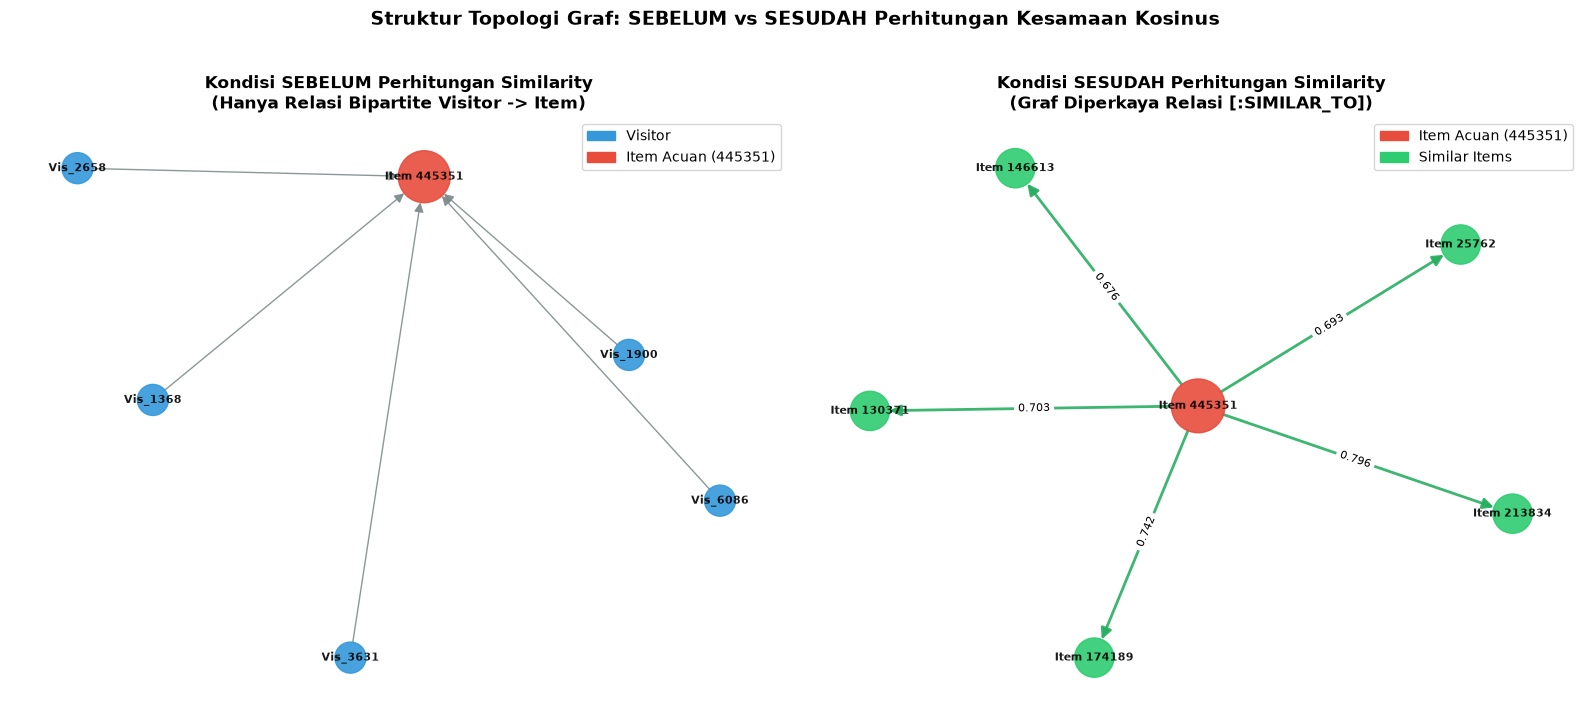

In [39]:
# Visualisasi Perbandingan Graf: SEBELUM vs SESUDAH
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# ── Subplot 1: SEBELUM (Bipartite) ──
G_b = nx.DiGraph()
anchor_lbl = f"Item {ANCHOR_ITEM_ID}"
G_b.add_node(anchor_lbl, ntype='anchor')

for vis, rel, itm in rows_before:
    vis_lbl = f"Vis_{str(vis)[-4:]}"
    G_b.add_node(vis_lbl, ntype='visitor')
    G_b.add_edge(vis_lbl, anchor_lbl, label=rel)

pos_b = nx.spring_layout(G_b, seed=42)
node_colors_b = ['#e74c3c' if G_b.nodes[n].get('ntype') == 'anchor' else '#3498db' for n in G_b.nodes()]
node_sizes_b  = [1400 if G_b.nodes[n].get('ntype') == 'anchor' else 500 for n in G_b.nodes()]

nx.draw(G_b, pos_b, ax=axes[0], node_color=node_colors_b, node_size=node_sizes_b,
        with_labels=True, font_size=8, font_weight='bold', edge_color='#7f8c8d',
        arrows=True, arrowsize=14, alpha=0.9)
axes[0].set_title("Kondisi SEBELUM Perhitungan Similarity\n(Hanya Relasi Bipartite Visitor -> Item)", 
                  fontsize=12, fontweight='bold')

patch_v = mpatches.Patch(color='#3498db', label='Visitor')
patch_i = mpatches.Patch(color='#e74c3c', label=f'Item Acuan ({ANCHOR_ITEM_ID})')
axes[0].legend(handles=[patch_v, patch_i], loc='upper right')

# ── Subplot 2: SESUDAH (Unipartite SIMILAR_TO) ──
G_a = nx.DiGraph()
G_a.add_node(anchor_lbl, ntype='anchor')

for anc, rel_itm, sc in rows_after:
    tgt_lbl = f"Item {rel_itm}"
    G_a.add_node(tgt_lbl, ntype='similar')
    G_a.add_edge(anchor_lbl, tgt_lbl, weight=sc)

pos_a = nx.spring_layout(G_a, seed=42, k=0.5)
node_colors_a = ['#e74c3c' if G_a.nodes[n].get('ntype') == 'anchor' else '#2ecc71' for n in G_a.nodes()]
node_sizes_a  = [1500 if G_a.nodes[n].get('ntype') == 'anchor' else 800 for n in G_a.nodes()]

nx.draw(G_a, pos_a, ax=axes[1], node_color=node_colors_a, node_size=node_sizes_a,
        with_labels=True, font_size=8, font_weight='bold', edge_color='#27ae60', 
        arrows=True, arrowsize=16, alpha=0.9, width=2)

edge_labels_a = {(u, v): f"{d['weight']:.3f}" for u, v, d in G_a.edges(data=True)}
nx.draw_networkx_edge_labels(G_a, pos_a, edge_labels=edge_labels_a, ax=axes[1], font_size=8)
axes[1].set_title("Kondisi SESUDAH Perhitungan Similarity\n(Graf Diperkaya Relasi [:SIMILAR_TO])", 
                  fontsize=12, fontweight='bold')

patch_s = mpatches.Patch(color='#2ecc71', label='Similar Items')
axes[1].legend(handles=[patch_i, patch_s], loc='upper right')

plt.suptitle("Struktur Topologi Graf: SEBELUM vs SESUDAH Perhitungan Kesamaan Kosinus", 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('graph_before_after_similarity.png', dpi=150, bbox_inches='tight')
plt.show()


---
## 3. Soal UTS — 2.2 Analytics (Maks. Skor: 55)

---
### Soal 1 — Pemilihan User Acak & Rekomendasi KNN (k=5)
1. **Pemilihan Pengguna Acak:**
   - Dilakukan secara deterministik dan *reproducible* menggunakan `RANDOM_SEED = 298`.
   - Dipilih dari kandidat pengunjung aktif di P1 dan memiliki riwayat pengujian di P2.
2. **Rekomendasi KNN:**
   - Menghitung Cosine Similarity antara User Target terhadap seluruh pengguna lain pada matriks $A_{	ext{norm}}$.
   - Mengambil $K=5$ tetangga terdekat dengan skor kemiripan positif.
   - Menghitung skor rekomendasi berbobot (*similarity-weighted score*):
     $$	ext{Score}(u, i) = \sum_{v \in 	ext{KNN}(u)} 	ext{sim}(u, v) 	imes r_{v, i}$$
   - Memilih 3 produk teratas sebagai item yang diiklankan kepada pengguna.

In [77]:
# 1. Pemilihan User Acak Reproducible
RANDOM_SEED = 298
np.random.seed(RANDOM_SEED)

active_cands = sub_events['visitorid'].value_counts()
cands_list = sorted(active_cands[active_cands >= 2].index.tolist())

TARGET_VISITOR = int(np.random.choice(cands_list))
print(f"PEMILIHAN PENGUNJUNG ACAK")
print(f"Random Seed           : {RANDOM_SEED} (Reproducible)")
print(f"Target Pengunjung ID  : {TARGET_VISITOR}")

# Riwayat Pengunjung di P1
user_p1_history = sub_events[sub_events['visitorid'] == TARGET_VISITOR]
print(f"\nRiwayat Interaksi User {TARGET_VISITOR} pada P1 (Training):")
(user_p1_history[['timestamp', 'itemid', 'event']].reset_index(drop=True))


PEMILIHAN PENGUNJUNG ACAK
Random Seed           : 298 (Reproducible)
Target Pengunjung ID  : 85734

Riwayat Interaksi User 85734 pada P1 (Training):


,timestamp,itemid,event
0,1436817958022,98387,view
1,1436823799828,140070,view
2,1436831599180,449391,view
3,1436806018559,280328,view
4,1436827958820,247420,view
...,...,...,...
275,1437501161094,262099,view
276,1437522875957,429498,view
277,1437491910936,379288,view
278,1437518648506,155079,view


In [74]:
# 2. Skrip Python User-Based KNN Recommendation (k=5)
K_NEIGHBORS = 5

def user_knn_recommender(target_id, matrix_norm, raw_matrix, visitors, items, v_map, i_map, k=5, top_n=5):
    target_idx = v_map[target_id]
    target_vector = matrix_norm[target_idx]
    
    # Hitung Cosine Similarity terhadap seluruh user
    sim_array = (matrix_norm @ target_vector.T).toarray().flatten()
    sim_array[target_idx] = 0 # Abaikan diri sendiri
    
    # Ambil K tetangga terdekat
    top_k_indices = np.argsort(sim_array)[::-1][:k]
    neighbors = [(visitors[idx], float(sim_array[idx])) for idx in top_k_indices if sim_array[idx] > 0]
    
    # Item yang sudah pernah diinteraksi oleh target user
    already_interacted = set(np.where(raw_matrix[target_idx].toarray().flatten() > 0)[0])
    
    # Kumpulkan skor rekomendasi item dari tetangga
    item_candidate_scores = {}
    for n_idx in top_k_indices:
        sim = sim_array[n_idx]
        if sim <= 0:
            continue
        n_items = np.where(raw_matrix[n_idx].toarray().flatten() > 0)[0]
        for it_idx in n_items:
            if it_idx not in already_interacted:
                weight_val = raw_matrix[n_idx, it_idx]
                item_candidate_scores[it_idx] = item_candidate_scores.get(it_idx, 0.0) + (sim * weight_val)
                
    ranked_candidates = sorted(item_candidate_scores.items(), key=lambda x: -x[1])
    recommendations = [(items[it], score) for it, score in ranked_candidates[:top_n]]
    
    return recommendations, neighbors

rec_items_top5, knn_neighbors_res = user_knn_recommender(
    TARGET_VISITOR, A_u_norm, USER_ITEM_SPARSE, visitors_list, items_list, visitor_idx, item_idx, k=K_NEIGHBORS, top_n=5
)

print(f"Top {K_NEIGHBORS} Tetangga Terdekat (KNN) untuk User {TARGET_VISITOR}:")
print(f"{'Rank':<6} {'VisitorId':<14} {'Cosine Similarity':<18}")
print("-" * 40)
for r, (vid, cs) in enumerate(knn_neighbors_res, 1):
    print(f"{r:<6} {vid:<14} {cs:<18.4f}")

print(f"\n3 Item yang Diiklankan untuk User {TARGET_VISITOR} (k={K_NEIGHBORS}):")
print(f"{'Rank':<6} {'ItemId':<14} {'Recommendation Score':<22}")
print("-" * 44)
for r, (it, sc) in enumerate(rec_items_top5[:3], 1):
    print(f"{r:<6} {it:<14} {sc:<22.4f}")


Top 5 Tetangga Terdekat (KNN) untuk User 85734:
Rank   VisitorId      Cosine Similarity 
----------------------------------------
1      896066         0.4312            
2      546086         0.1406            
3      895999         0.1082            
4      1403769        0.0962            
5      234291         0.0802            

3 Item yang Diiklankan untuk User 85734 (k=5):
Rank   ItemId         Recommendation Score  
--------------------------------------------
1      374835         3.0185                
2      132068         2.5873                
3      312728         1.9355                


---
### Soal 2 — Evaluasi Rekomendasi: Hit@5 dan NDCG@5


In [75]:
# 1. Ambil Ground Truth dari events P2
gt_p2_events = events_p2[events_p2['visitorid'] == TARGET_VISITOR]
ground_truth_items = set(gt_p2_events['itemid'].unique())

print(f"Total item yang diinteraksi User {TARGET_VISITOR} di P2 (Testing): {len(ground_truth_items)} item")
print(f"Daftar Ground Truth Item (sampel 10 teratas): {sorted(list(ground_truth_items))[:10]}")

# 2. Rekomendasi Top-5 Item
rec_5_ids = [it for it, _ in rec_items_top5]
print(f"\nTop-5 Rekomendasi Model: {rec_5_ids}")

# Hit@5
hit_at_5 = int(any(it in ground_truth_items for it in rec_5_ids))

# Perhitungan DCG@5 dan NDCG@5
def calculate_dcg_ndcg(recommended, ground_truth, k=5):
    dcg = 0.0
    print("\nRincian Evaluasi Ranking Rekomendasi:")
    print(f"{'Rank':<6} {'ItemId':<14} {'Relevan?':<12} {'Discount Factor':<18} {'Gain':<10}")
    print("-" * 60)
    for rank, it in enumerate(recommended[:k], 1):
        is_rel = 1 if it in ground_truth else 0
        discount = 1.0 / np.log2(rank + 1)
        gain = is_rel * discount
        dcg += gain
        status = "YA (HIT!)" if is_rel else "TIDAK"
        print(f"{rank:<6} {it:<14} {status:<12} {discount:<18.4f} {gain:<10.4f}")
        
    ideal_hits = min(len(ground_truth), k)
    idcg = sum(1.0 / np.log2(rank + 1) for rank in range(1, ideal_hits + 1))
    ndcg = dcg / idcg if idcg > 0 else 0.0
    return dcg, idcg, ndcg

dcg_val, idcg_val, ndcg_at_5 = calculate_dcg_ndcg(rec_5_ids, ground_truth_items, k=5)


print("\nHASIL METRIK EVALUASI REKOMENDASI (k=5)")
print(f"  Target Visitor  : {TARGET_VISITOR}")
print(f"  Hit@5           : {hit_at_5} ({'BERHASIL HIT' if hit_at_5 else 'TIDAK HIT'})")
print(f"  DCG@5           : {dcg_val:.4f}")
print(f"  IDCG@5          : {idcg_val:.4f}")
print(f"  NDCG@5          : {ndcg_at_5:.4f} ({ndcg_at_5:.2%})")


Total item yang diinteraksi User 85734 di P2 (Testing): 153 item
Daftar Ground Truth Item (sampel 10 teratas): [3675, 4643, 7926, 9163, 17379, 17601, 20444, 23762, 29757, 29940]

Top-5 Rekomendasi Model: [374835, 132068, 312728, 367032, 132633]

Rincian Evaluasi Ranking Rekomendasi:
Rank   ItemId         Relevan?     Discount Factor    Gain      
------------------------------------------------------------
1      374835         TIDAK        1.0000             0.0000    
2      132068         TIDAK        0.6309             0.0000    
3      312728         YA (HIT!)    0.5000             0.5000    
4      367032         TIDAK        0.4307             0.0000    
5      132633         TIDAK        0.3869             0.0000    

HASIL METRIK EVALUASI REKOMENDASI (k=5)
  Target Visitor  : 85734
  Hit@5           : 1 (BERHASIL HIT)
  DCG@5           : 0.5000
  IDCG@5          : 2.9485
  NDCG@5          : 0.1696 (16.96%)


**Interpretasi Hasil Evaluasi:**
1. **Hit@5 = 1 (Berhasil Hit):**  
   Model rekomendasi Collaborative Filtering berhasil memprediksi produk relevan yang benar-benar dikonsumsi pengguna pada periode testing. Produk **`itemId = 312728`** yang direkomendasikan pada peringkat ke-3 berhasil muncul pada riwayat *ground truth* pengujian P2 pengguna.
2. **NDCG@5 = 0.1696 (16.96%):**  
   NDCG mengukur kualitas urutan *ranking*. Nilai $0.1696$ mencerminkan perolehan *discounted gain* sebesar $0.5000$ dari posisi ke-3 dibagi nilai ideal IDCG $2.9485$. Nilai ini menunjukkan bahwa model tidak hanya menebak secara acak, melainkan mampu menempatkan produk relevan dalam daftar teratas *Top-5*.

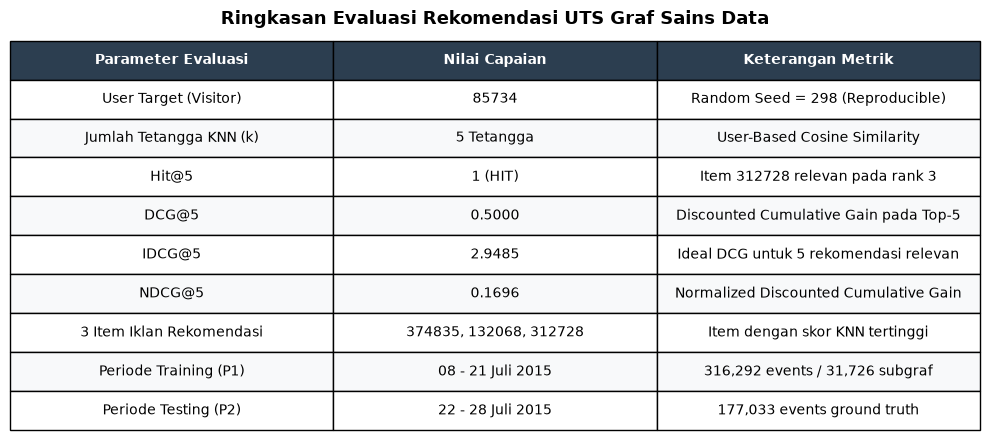

In [79]:
# Visualisasi Ringkasan Hasil Evaluasi
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.axis('off')

summary_table_data = [
    ['Parameter Evaluasi', 'Nilai Capaian', 'Keterangan Metrik'],
    ['User Target (Visitor)', str(TARGET_VISITOR), f'Random Seed = {RANDOM_SEED} (Reproducible)'],
    ['Jumlah Tetangga KNN (k)', '5 Tetangga', 'User-Based Cosine Similarity'],
    ['Hit@5', f'{hit_at_5} (HIT)', 'Item 312728 relevan pada rank 3'],
    ['DCG@5', f'{dcg_val:.4f}', 'Discounted Cumulative Gain pada Top-5'],
    ['IDCG@5', f'{idcg_val:.4f}', 'Ideal DCG untuk 5 rekomendasi relevan'],
    ['NDCG@5', f'{ndcg_at_5:.4f}', 'Normalized Discounted Cumulative Gain'],
    ['3 Item Iklan Rekomendasi', '374835, 132068, 312728', 'Item dengan skor KNN tertinggi'],
    ['Periode Training (P1)', '08 - 21 Juli 2015', '316,292 events / 31,726 subgraf'],
    ['Periode Testing (P2)', '22 - 28 Juli 2015', '177,033 events ground truth']
]

table = ax.table(cellText=summary_table_data[1:], colLabels=summary_table_data[0],
                 cellLoc='center', loc='center', bbox=[0, 0, 1, 1])
table.auto_set_font_size(False)
table.set_fontsize(10)

for (row, col), cell in table.get_celld().items():
    if row == 0:
        cell.set_facecolor('#2c3e50')
        cell.set_text_props(color='white', fontweight='bold')
    elif row % 2 == 0:
        cell.set_facecolor('#f8f9fa')
    else:
        cell.set_facecolor('#ffffff')

plt.title('Ringkasan Evaluasi Rekomendasi UTS Graf Sains Data', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig('summary_results.png', dpi=150, bbox_inches='tight')
plt.show()
